# ProtoStar — 30-year average / linear-trend blend

This notebook tests a deliberately simple alternative to the starter Random Forest: a weighted blend of two official reference baselines. It does not use data after 2018 and does not write `submission.csv`.

**Question:** for each climate metric, should a forecast lean more on a stable 30-year average, on a 30-year linear trend, or somewhere between them?

## Method and leakage protection

A blend weight of `0` is the 30-year average; a weight of `1` is the linear trend. We select a weight using an earlier development period—train through 2002, predict 2003–2010—then freeze that choice and evaluate it on the existing final backtest: train through 2010, predict 2011–2018.

This keeps model selection separate from the final historical evaluation. The notebook reads the curated data through `code/common.py`, which enforces the 2018 cutoff.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (candidate / "code" / "common.py").exists():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Open this notebook inside the ProtoStar-Challenge repository.")

CODE_DIR = PROJECT_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from common import CUTOFF_YEAR, FORECAST_YEARS, METRICS, load_valid_annual, mae, thirty_year_mean, wide
from starter_model import backtest, baselines

annual = load_valid_annual()
print(f"Loaded {len(annual):,} city-years; latest permissible weather year: {CUTOFF_YEAR}.")

Loaded 28,052 city-years; latest permissible weather year: 2018.


## Blend helpers

The helper below reuses the repository's official baseline implementation. Only city-years that the challenge would score are included: valid observed outcomes, and at least 10 valid years in the relevant 30-year baseline window.

In [2]:
WEIGHTS = np.array([0.00, 0.25, 0.50, 0.75, 1.00])

def blend_predictions(table: pd.DataFrame, last_train_year: int, years: list[int], trend_weight: float) -> pd.DataFrame:
    """0.0 = 30-year average; 1.0 = 30-year linear trend."""
    references = baselines(table, last_train_year, years)
    average = references["30_year_average"]
    trend = references["linear_trend"]
    return (1 - trend_weight) * average + trend_weight * trend

def eligible_actuals(table: pd.DataFrame, last_train_year: int, years: list[int]) -> pd.DataFrame:
    eligible_city = thirty_year_mean(table, last_train_year).notna()
    return table[years].where(eligible_city, axis=0)

def score_weight_grid(annual: pd.DataFrame, last_train_year: int, years: list[int], weights: np.ndarray) -> pd.DataFrame:
    rows = []
    for metric in METRICS:
        table = wide(annual, metric)
        actual = eligible_actuals(table, last_train_year, years)
        for weight in weights:
            prediction = blend_predictions(table, last_train_year, years, weight)
            rows.append({
                "metric": metric,
                "trend_weight": weight,
                "mae": mae(actual.stack(future_stack=True), prediction.stack(future_stack=True)),
            })
    return pd.DataFrame(rows)

## 1. Choose weights on the development period

This is the only place where we select a weight. Each metric may receive a different weight because precipitation, extreme heat, average temperature, and CDD behave differently.

In [3]:
DEVELOPMENT_LAST_TRAIN_YEAR = 2002
development_years = list(range(2003, 2011))
development_scores = score_weight_grid(annual, DEVELOPMENT_LAST_TRAIN_YEAR, development_years, WEIGHTS)
development_table = development_scores.pivot(index="trend_weight", columns="metric", values="mae").round(3)
development_table

metric,annual_avg_temp,cdd,hottest_day_temp,total_precip_in
trend_weight,,,,
0.00,1.075,171.344,2.552,5.801
0.25,0.991,163.741,2.497,5.789
0.50,0.947,159.475,2.488,5.843
0.75,0.948,159.457,2.525,5.960
1.00,0.998,163.153,2.604,6.139


In [4]:
selected_weights = (development_scores.sort_values(["metric", "mae"])
    .groupby("metric", as_index=False)
    .first()[["metric", "trend_weight", "mae"]]
    .rename(columns={"mae": "development_mae"}))
selected_weights

,metric,trend_weight,development_mae
0,annual_avg_temp,0.50,0.947076
1,cdd,0.75,159.457106
2,hottest_day_temp,0.50,2.487581
3,total_precip_in,0.25,5.788602


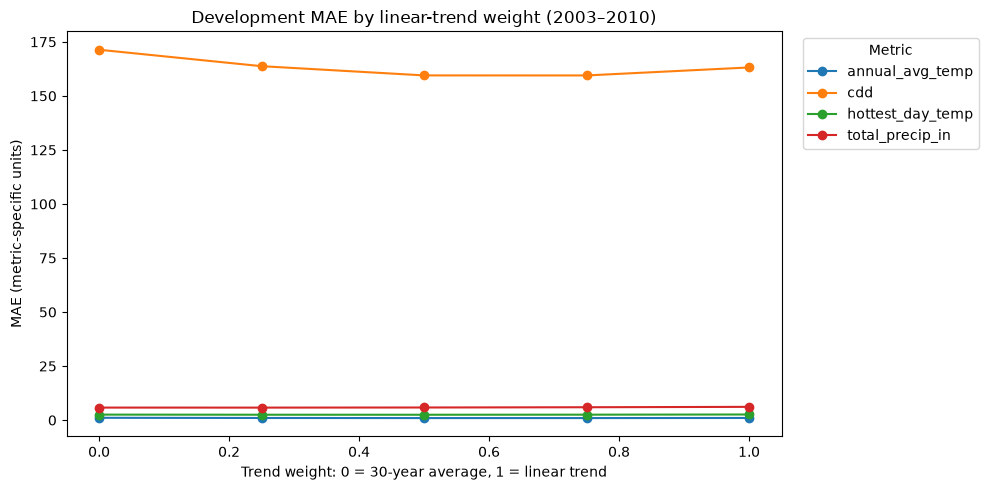

In [5]:
ax = development_table.plot(marker="o", figsize=(10, 5))
ax.set_title("Development MAE by linear-trend weight (2003–2010)")
ax.set_xlabel("Trend weight: 0 = 30-year average, 1 = linear trend")
ax.set_ylabel("MAE (metric-specific units)")
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

## 2. Final historical evaluation

The weights above are now frozen. We compare the fixed blend with the starter Random Forest and all three official references on 2011–2018—years that were not used to choose the weights.

In [6]:
FINAL_LAST_TRAIN_YEAR = 2010
final_years = list(range(2011, CUTOFF_YEAR + 1))

# Existing repository benchmark: starter RF plus three official reference rules.
comparison = backtest(annual, last_year=FINAL_LAST_TRAIN_YEAR)

blend_rows = []
for row in selected_weights.itertuples(index=False):
    table = wide(annual, row.metric)
    actual = eligible_actuals(table, FINAL_LAST_TRAIN_YEAR, final_years)
    prediction = blend_predictions(table, FINAL_LAST_TRAIN_YEAR, final_years, row.trend_weight)
    blend_rows.append({"model": "selected_average_trend_blend", "metric": row.metric, "mae": mae(
        actual.stack(future_stack=True), prediction.stack(future_stack=True)
    )})

comparison = pd.concat([comparison, pd.DataFrame(blend_rows)], ignore_index=True)
reference_mae = comparison.loc[comparison["model"].eq("30_year_average"), ["metric", "mae"]].set_index("metric")["mae"]
comparison["skill_vs_30_year_average"] = 1 - comparison["mae"] / comparison["metric"].map(reference_mae)
comparison.pivot(index="model", columns="metric", values="mae").round(3)

metric,annual_avg_temp,cdd,hottest_day_temp,total_precip_in
model,,,,
30_year_average,1.656,211.691,2.555,6.180
last_year_repeated,1.670,215.174,3.251,8.552
linear_trend,1.425,174.598,2.700,6.529
selected_average_trend_blend,1.501,178.810,2.540,6.156
starter_rf_lags,1.814,197.350,3.273,7.568


In [7]:
final_score = 100 * comparison.groupby("model")["skill_vs_30_year_average"].mean().clip(lower=0)
display(comparison.sort_values(["metric", "mae"]).round(4))
print("Overall score (higher is better):")
final_score.sort_values(ascending=False).round(2)

,model,metric,mae,skill,skill_vs_30_year_average
3,linear_trend,annual_avg_temp,1.4255,0.1392,0.1392
16,selected_average_trend_blend,annual_avg_temp,1.5013,NaN,0.0934
2,30_year_average,annual_avg_temp,1.6560,0.0000,0.0000
1,last_year_repeated,annual_avg_temp,1.6704,-0.0087,-0.0087
0,starter_rf_lags,annual_avg_temp,1.8144,-0.0957,-0.0957
15,linear_trend,cdd,174.5978,0.1752,0.1752
17,selected_average_trend_blend,cdd,178.8104,NaN,0.1553
12,starter_rf_lags,cdd,197.3504,0.0677,0.0677
14,30_year_average,cdd,211.6906,0.0000,0.0000
13,last_year_repeated,cdd,215.1745,-0.0165,-0.0165


Overall score (higher is better):


model
selected_average_trend_blend    6.47
linear_trend                    5.03
30_year_average                 0.00
last_year_repeated              0.00
starter_rf_lags                 0.00
Name: skill_vs_30_year_average, dtype: float64

## 3. Forecast preview (no file output)

This constructs in-memory forecasts using all permissible history through 2018 and the previously selected weights. It is a preview only: do not copy values manually into `submission.csv`. If the blend holds up across further historical folds, promote its implementation into `code/` and regenerate the submission through code.

In [8]:
weight_by_metric = selected_weights.set_index("metric")["trend_weight"].to_dict()
blend_forecasts = {
    metric: blend_predictions(wide(annual, metric), CUTOFF_YEAR, FORECAST_YEARS, weight)
    for metric, weight in weight_by_metric.items()
}
city_id = next(iter(blend_forecasts.values())).index[0]
pd.DataFrame({metric: values.loc[city_id] for metric, values in blend_forecasts.items()})

,annual_avg_temp,cdd,hottest_day_temp,total_precip_in
2019,66.761966,1712.012839,104.920223,12.489111
2020,66.803822,1728.362588,105.040017,12.455384
2021,66.845679,1744.712337,105.159810,12.421656
2022,66.887535,1761.062085,105.279604,12.387929
2023,66.929392,1777.411834,105.399397,12.354201
2024,66.971248,1793.761583,105.519190,12.320474
2025,67.013105,1810.111332,105.638984,12.286746


## Key insights

- The development period selected different mixes by metric: **50% trend** for average temperature, **25%** for precipitation, **50%** for hottest-day temperature, and **75%** for CDD. This supports using more trend where the climate signal is persistent and more averaging where annual noise dominates.
- On the untouched 2011–2018 evaluation, the blend has the highest overall challenge-style score: **6.47**, compared with **5.03** for the pure linear trend and **0** for the starter RF.
- The blend beats the 30-year average on all four metrics and beats the starter RF by a wide margin. Its MAEs are `1.50 °F` for average temperature, `6.16 in` for precipitation, `2.54 °F` for hottest day, and `178.81 °F-days` for CDD.
- Pure linear trend is still individually better for average temperature and CDD, while the blend is better for precipitation and hottest day. The blended score wins because it balances performance across all four metrics.
- Improvements for precipitation and hottest day are small and may be within historical variability. Validate the weight-selection procedure across additional expanding-window folds before promoting it into `code/`.

## Next todo: XGBoost

The next controlled experiment is XGBoost, compared against this blend and every existing baseline using the same cutoff guard and chronological evaluation. Candidate features include lags, rolling summaries, recent trends, latitude/longitude, and station-change information. XGBoost should earn its added complexity through historical backtests; add it to the project dependencies only when that experiment begins.